# 05 — Recalibration and statistical uncertainty

**Goal:** answer two questions about the scorecard from notebooks 03–04.

1. Its PDs are too low on recent loans. Can a recalibration fix that? The recalibration is
   **fitted on 2014 loans** and **tested once on 2015 loans**, so the test is honest.
2. How precise are the results? **Bootstrap confidence intervals** for every metric, and a paired
   test of the scorecard against the challenger.

In [1]:
import os, sys, pickle
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pdmodel import config as C
pd.set_option("display.float_format", "{:.4f}".format)
PROC = ROOT / "data" / "processed"
from pdmodel import bootstrap as B, calibration as K, model, plots, validation as V

In [2]:
S = pd.read_pickle(PROC / "samples.pkl")
M = pd.read_pickle(PROC / "model.pkl")
card, gbm = M["scorecard"], M["challenger"]
y   = {k: v["default"].to_numpy() for k, v in S.items()}
pd_ = {k: card.predict_pd(v) for k, v in S.items()}
sc  = {k: card.score(v) for k, v in S.items()}
gpd = {k: model.challenger_pd(gbm, v) for k, v in S.items()}
edges = V.grade_edges(sc["train"])
grade = {k: V.assign_grade(sc[k], edges) for k in S}

## 1. Calibration of the model as developed

Two summaries, both from a logistic regression of the outcome on logit(PD):

- **calibration intercept** (logit(PD) as a fixed offset): 0 is ideal; positive means the PDs are too low;
- **calibration slope**: 1 is ideal; below 1 means the PDs are too spread out.

In [3]:
pd.DataFrame({k: K.calibration_metrics(y[k], pd_[k]) for k in S}).T

,mean_pd,observed_dr,eo_ratio,brier,log_loss,cal_intercept,cal_slope
train,0.1263,0.1263,1.0000,0.1065,0.3616,-0.0000,1.0000
test,0.1261,0.1263,0.9983,0.1069,0.3632,0.0021,0.9534
calib,0.1307,0.1373,0.9520,0.1148,0.3841,0.0589,0.9462
oot,0.1254,0.1489,0.8426,0.1230,0.4055,0.2059,0.9546


## 2. Choose the recalibration on 2014 loans only

Rule (`calibration.choose_method`), applied to the calibration sample alone:

- re-estimate the **slope** only if it differs from 1 by more than 0.10, and significantly;
- otherwise re-estimate the **intercept** if it differs significantly from 0;
- otherwise leave the PDs alone.

A measured bias in the PD level is always corrected: validation tolerances decide whether a model
passes, not whether a known bias is worth removing.

In [4]:
rc = K.compare_methods(y["calib"], pd_["calib"], y["oot"], pd_["oot"], grade["oot"],
                       C.RECALIBRATION_METHODS, C.RECAL_SLOPE_MATERIAL)
print("chosen:", rc["method"], "-", rc["reason"])

chosen: intercept - calibration intercept +0.059 (s.e. 0.007) differs significantly from 0, while the slope 0.946 is within 0.1 of 1


## 3. Test every method once on 2015 loans

All three are fitted on 2014. Recalibration maps PDs through a monotonic function, so Gini, AUC
and KS cannot change; only the PD level does.

In [5]:
rc["table"]

,a,b,auc,gini,ks,mean_pd,observed_dr,eo_ratio,brier,log_loss,cal_intercept,cal_slope,grades_failing
method,,,,,,,,,,,,,
none,0.0000,1.0000,0.6480,0.2961,0.2125,0.1254,0.1489,0.8426,0.1230,0.4055,0.2059,0.9546,7.0000
intercept,0.0589,1.0000,0.6480,0.2961,0.2125,0.1318,0.1489,0.8854,0.1227,0.4043,0.1470,0.9546,6.0000
intercept_slope,-0.0377,0.9462,0.6480,0.2961,0.2125,0.1321,0.1489,0.8872,0.1227,0.4043,0.1441,1.0089,6.0000


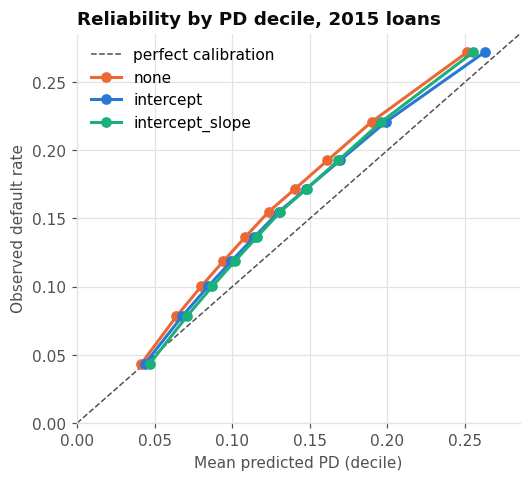

,none,intercept,intercept_slope
decile,,,
1,0.9506,1.0056,1.0763
2,0.8189,0.8651,0.9043
3,0.7984,0.8427,0.8699
4,0.7944,0.8377,0.8570
5,0.7948,0.8375,0.8501
6,0.7971,0.8392,0.8457
7,0.8182,0.8604,0.8611
8,0.8379,0.8801,0.8744
9,0.8593,0.9010,0.8878


In [6]:
plots.calibration_plot(rc["deciles"], colors=plots.METHOD_COLORS, title="Reliability by PD decile, 2015 loans")
plt.show()
pd.concat({m: t["eo_ratio"] for m, t in rc["deciles"].items()}, axis=1)

### Binomial test by grade, before and after

Grade = 7 equal-population score bands from notebook 04. A red grade means the PDs are too low there.

In [7]:
cm = model.CalibratedScorecard(card, rc["recalibrators"][rc["method"]], edges)
pdc = {k: cm.predict_pd(v) for k, v in S.items()}
before = V.binomial_test_by_grade(y["oot"], pd_["oot"], grade["oot"])
after = V.binomial_test_by_grade(y["oot"], pdc["oot"], grade["oot"])
pd.concat({"as developed": before[["mean_pd", "observed_dr", "result"]],
           "recalibrated": after[["mean_pd", "result"]]}, axis=1)

as developed                              recalibrated                 
           mean_pd observed_dr           result      mean_pd           result
grade                                                                        
1           0.0460      0.0508  RED: PD too low       0.0486            AMBER
2           0.0738      0.0919  RED: PD too low       0.0779  RED: PD too low
3           0.0951      0.1190  RED: PD too low       0.1003  RED: PD too low
4           0.1163      0.1470  RED: PD too low       0.1225  RED: PD too low
5           0.1405      0.1703  RED: PD too low       0.1477  RED: PD too low
6           0.1724      0.2057  RED: PD too low       0.1809  RED: PD too low
7           0.2378      0.2601  RED: PD too low       0.2485  RED: PD too low

## 4. Why the 2014 recalibration falls short

Default rates and the model's mean PD (as developed) by issue quarter. If the borrowers' profile
explained the rising default rate, the mean PD would rise with it.

In [8]:
both = pd.concat([S["calib"].assign(pd=pd_["calib"]), S["oot"].assign(pd=pd_["oot"])])
both.groupby(both["issue_d"].dt.to_period("Q")).agg(
    loans=("default", "size"), observed_dr=("default", "mean"), mean_pd_as_developed=("pd", "mean"))

,loans,observed_dr,mean_pd_as_developed
issue_d,,,
2014Q1,34074,0.1287,0.1304
2014Q2,37881,0.1355,0.1305
2014Q3,40595,0.1363,0.1300
2014Q4,50020,0.1453,0.1315
2015Q1,56568,0.1483,0.1300
2015Q2,64222,0.1538,0.1276
2015Q3,73567,0.1458,0.1235
2015Q4,88669,0.1482,0.1226


## 5. Bootstrap confidence intervals

Each resample re-weights the 2015 loans, and every metric and model is computed on the same
resample. Two schemes:

- **loan**: draw single loans with replacement (treats loans as independent);
- **month**: draw whole issue months (block bootstrap). Loans issued in the same month face the
  same economy, so their outcomes are correlated. This is the main result.

The scorecard is the recalibrated one; the challenger is intercept-recalibrated on 2014 the same
way so their PD levels are comparable. 1,000 resamples per scheme takes about four minutes.

In [9]:
g_recal = K.Recalibrator("intercept").fit(y["calib"], gpd["calib"])
preds = {"scorecard": pdc["oot"], "challenger": g_recal.transform(gpd["oot"])}
point = B.point_estimates(y["oot"], preds)
ci, paired = {}, {}
for scheme, groups in {"month": B.month_groups(S["oot"]["issue_d"]), "loan": None}.items():
    draws = B.bootstrap(y["oot"], preds, groups, n_draws=C.BOOTSTRAP_DRAWS, seed=C.RANDOM_STATE)
    ci[scheme] = B.intervals(draws, point, C.CI_LEVEL)
    paired[scheme] = B.paired_difference(draws, point, "scorecard", "challenger", level=C.CI_LEVEL)
ci, paired = pd.concat(ci, names=["scheme"]), pd.concat(paired, names=["scheme"])
B.summary_table(ci)

estimate 95% interval, month blocks  \
model      metric                                              
scorecard  gini            0.2961            0.2916 – 0.3003   
           ks              0.2125            0.2083 – 0.2174   
           auc             0.6480            0.6458 – 0.6502   
           brier           0.1227            0.1206 – 0.1248   
           log_loss        0.4043            0.3989 – 0.4098   
           eo_ratio        0.8854            0.8687 – 0.9021   
           cal_intercept   0.1470            0.1242 – 0.1705   
           cal_slope       0.9546            0.9430 – 0.9666   
challenger gini            0.3176            0.3131 – 0.3218   
           ks              0.2279            0.2235 – 0.2332   
           auc             0.6588            0.6565 – 0.6609   
           brier           0.1219            0.1198 – 0.1239   
           log_loss        0.4012            0.3959 – 0.4064   
           eo_ratio        0.9051            0.8899 – 0.9203   
           cal_intercept   0.1215            0.1010 – 0.1425   
           cal_slope       0.9477            0.9364 – 0.9600   

                         95% interval, loans s.e. month / loan  
model      metric                                               
scorecard  gini              0.2902 – 0.3017   0.0022 / 0.0028  
           ks                0.2079 – 0.2178   0.0024 / 0.0025  
           auc               0.6451 – 0.6508   0.0011 / 0.0014  
           brier             0.1218 – 0.1237   0.0011 / 0.0005  
           log_loss          0.4020 – 0.4068   0.0028 / 0.0012  
           eo_ratio          0.8776 – 0.8932   0.0086 / 0.0039  
           cal_intercept     0.1363 – 0.1580   0.0119 / 0.0054  
           cal_slope         0.9346 – 0.9739   0.0063 / 0.0099  
challenger gini              0.3117 – 0.3231   0.0022 / 0.0028  
           ks                0.2235 – 0.2331   0.0025 / 0.0025  
           auc               0.6559 – 0.6615   0.0011 / 0.0014  
           brier             0.1210 – 0.1228   0.0011 / 0.0005  
           log_loss          0.3988 – 0.4037   0.0027 / 0.0012  
           eo_ratio          0.8972 – 0.9132   0.0079 / 0.0040  
           cal_intercept     0.1106 – 0.1323   0.0107 / 0.0055  
           cal_slope         0.9282 – 0.9659   0.0057 / 0.0093

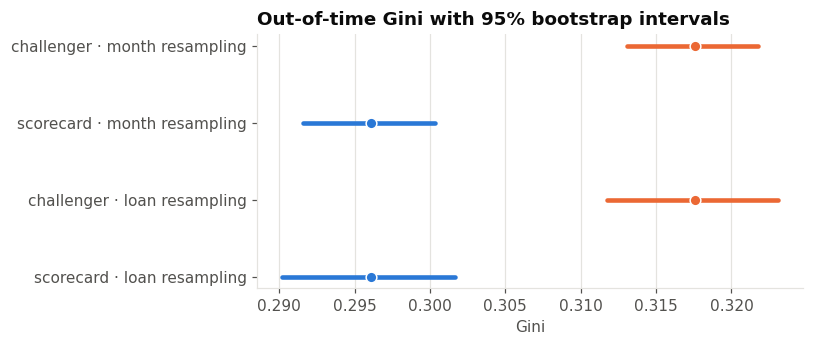

In [10]:
plots.ci_plot(ci); plt.show()

## 6. Scorecard vs challenger, paired

Challenger minus scorecard on the same resamples: positive Gini/KS means the challenger ranks
better; negative Brier/log loss means it is more accurate.

In [11]:
paired

difference   lower   upper  share_of_draws_b_better  \
scheme metric                                                          
month  gini          0.0215  0.0183  0.0241                   1.0000   
       ks            0.0154  0.0114  0.0196                   1.0000   
       brier        -0.0008 -0.0009 -0.0007                   1.0000   
       log_loss     -0.0032 -0.0036 -0.0027                   1.0000   
loan   gini          0.0215  0.0186  0.0245                   1.0000   
       ks            0.0154  0.0120  0.0192                   1.0000   
       brier        -0.0008 -0.0009 -0.0007                   1.0000   
       log_loss     -0.0032 -0.0036 -0.0028                   1.0000   

                 significant  
scheme metric                 
month  gini             True  
       ks               True  
       brier            True  
       log_loss         True  
loan   gini             True  
       ks               True  
       brier            True  
       log_loss         True

In [12]:
pd.to_pickle({"calibrated_model": cm, "recalibration": rc, "challenger_recal": g_recal,
               "ci": ci, "paired": paired}, PROC / "validation.pkl")
print("saved data/processed/validation.pkl")

saved data/processed/validation.pkl


## Findings
- Before recalibration the model predicts 12.54% on 2015 loans against 14.89% observed (calibration
  intercept +0.206); all seven grades fail the binomial test.
- On 2014 loans alone the intercept is +0.059 (s.e. 0.007) and the slope 0.946, so the rule
  re-estimates the intercept only. Adding a slope changes the 2015 Brier score by less than 0.00001.
- The 2014 intercept raises the 2015 mean PD to 13.18%, closing only about a quarter of the gap;
  6 of 7 grades still fail. Between 2014 and 2015 the default rate rose from 13.7% to 14.9% while
  the model's mean PD *fell*, so the drift is something the inputs do not capture.
- Out-of-time Gini is 0.296 (95% interval 0.292–0.300). Month-block intervals are about twice as
  wide as loan-level ones for calibration measures, but similar for Gini: the uncertainty in the PD
  level is understated if loans are treated as independent.
- The challenger beats the scorecard on every resample (+0.022 Gini, interval +0.018 to +0.024),
  but by less than the 0.03 materiality threshold, and its calibration fails as well.